# Trabalho 2 – Mineração de Dados (Age of Mythology) – versão corrigida

Mudanças em relação à versão anterior: (1) valores ausentes tratados **dentro** do pipeline (mediana calculada só no treino) em vez de `fillna(0)`; (2) `does_attack` removido (é sempre 1 no arquivo de teste); (3) novos atributos derivados; (4) validação cruzada **estratificada e repetida** no lugar de uma única `KFold`; (5) inclusão de Random Forest, Extra Trees, Regressão Logística, SVM e um ensemble por votação; (6) validação **aninhada** para a estimativa final de acurácia.

## 1. Carga e limpeza dos dados

In [1]:
import pandas as pd

In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
caminho = "https://www-usr.inf.ufsm.br/~joaquim/UFSM/DM/ds/AgeOfMythology_work.csv"
df = pd.read_csv(caminho, dtype="string", keep_default_na=False, encoding="utf-8")

In [3]:
df

,Unit,Age,Cost,Pop,DmgHack,DmgPierce,DmgCrush,Range,HP,ArmorHack,ArmorPierce,ArmorCrush,Speed,LOS,Train time,Bonus,Other,Class
0,Pegasus,1,50F 2Fv,2,--,--,--,0,140,50,50,99,5,18,6,,,Myth Unit
1,Centaur,2,200W 15Fv,3,--,12,--,12,220,25,35,80,5,20,19,"Myth units, -Heroes",,Myth Unit
2,Cyclops,2,250F 22Fv,4,15,--,12,2,600,40,50,80,3.2,16,20,Myth units,,Myth Unit
3,Minotaur,2,200F 16Fv,4,15,--,10,2,300,60,50,80,4,20,20,Myth units,,Myth Unit
4,Hydra,3,250F 28Fv,5,20,--,10,3,800,60,40,80,4,16,20,"Myth units, -Heroes",,Myth Unit
5,Manticore,3,300W 28Fv,5,--,11**,--,16,420,30,60,80,4.3,20,17,"Myth units, -Heroes",,Myth Unit
6,Nemean Lion,3,200G 25Fv,4,20,--,10,1,660,30,60,80,4.8,16,20,"Myth units, -Heroes",,Myth Unit
7,Colossus,4,300G 40Fv,5,20,--,50,3,1100_,50,80,80,2.4,16,24,"Myth units, -Heroes",,Myth Unit
8,Chimera,4,300G 30Fv,4,20,--,--,1,800,60,60,80,5.3,16,20,"Myth units, -Heroes",,Myth Unit
9,Medusa,4,250G 40Fv,5,--,15,12.5,10,360,60,70,80,4.3,18,20,"Myth units, -Heroes",,Myth Unit


Limpeza dos dados

In [4]:
import pandas as pd

RECURSOS = {
    "F": "cost_food",
    "W": "cost_wood",
    "G": "cost_gold",
    "Fv": "cost_favor",
}

COLUNAS_NUMERICAS = [
    "age", "pop", "dmg_hack", "dmg_pierce", "dmg_crush",
    "range", "hp", "armor_hack", "armor_pierce",
    "armor_crush", "speed", "los", "train_time",
]


def extrair_custos(valor):
    if pd.isna(valor) or valor in ("", "--"):
        return {nome: 0 for nome in RECURSOS.values()}

    custos = {nome: 0 for nome in RECURSOS.values()}

    for item in valor.replace(",", " ").split():
        recurso = next(
            (r for r in RECURSOS if item.endswith(r)),
            None
        )

        if recurso is None:
            raise ValueError(f"Custo inválido: {item}")

        quantidade = item.removesuffix(recurso)

        if not quantidade.isdigit():
            raise ValueError(f"Custo inválido: {item}")

        custos[RECURSOS[recurso]] += int(quantidade)

    return custos


def limpar_dataset(df) -> pd.DataFrame:
    df = df.copy()

    # Padroniza espaços e valores ausentes
    df.columns = [
        " ".join(col.replace("\u00a0", " ").split())
        for col in df.columns
    ]

    for coluna in df.columns:
        df[coluna] = df[coluna].map(
            lambda x: " ".join(x.replace("\u00a0", " ").split())
            if isinstance(x, str) else x
        )
    
    df = df.replace("", pd.NA)

    # Renomeia colunas
    df = df.rename(columns={
        "Unit": "unit",
        "Age": "age",
        "Cost": "cost_raw",
        "Pop": "pop",
        "DmgHack": "dmg_hack",
        "DmgPierce": "dmg_pierce",
        "DmgCrush": "dmg_crush",
        "Range": "range",
        "HP": "hp",
        "ArmorHack": "armor_hack",
        "ArmorPierce": "armor_pierce",
        "ArmorCrush": "armor_crush",
        "Speed": "speed",
        "LOS": "los",
        "Train time": "train_time",
        "Bonus": "bonus",
        "Other": "other",
        "Class": "unit_class",
    })

    # Corrige erros de escrita
    for coluna in ["unit_class", "bonus"]:
        df[coluna] = df[coluna].str.replace(
            "Infantary", "Infantry", regex=False
        )

    # Extrai custos
    custos = df["cost_raw"].apply(extrair_custos)
    custos = pd.DataFrame(custos.tolist(), index=df.index)

    for coluna in custos.columns:
        df[coluna] = custos[coluna].astype("Int64")

    # Remove marcações dos danos
    for coluna in ["dmg_hack", "dmg_pierce", "dmg_crush"]:
        df[coluna] = df[coluna].str.replace("*", "", regex=False)

    # Corrige HP
    df["hp"] = df["hp"].str.removesuffix("_")

    # Remove símbolo de porcentagem das armaduras
    for coluna in ["armor_hack", "armor_pierce", "armor_crush"]:
        df[coluna] = df[coluna].str.removesuffix("%")

    colunas_dmg = ["dmg_hack", "dmg_pierce", "dmg_crush"]

    df["does_attack"] = df[colunas_dmg].ne("--").any(axis=1).astype(int)


    # Converte colunas numéricas
    for coluna in COLUNAS_NUMERICAS:

        substituicoes = {
            "--": 0 if coluna.startswith("dmg_") else pd.NA,
            "none": pd.NA,
        }

        df[coluna] = pd.to_numeric(
            df[coluna].replace(substituicoes),
            errors="raise"
        )

    # Define tipos
    colunas_inteiras = [
        "age", "pop", "range", "hp",
        "armor_hack", "armor_pierce", "armor_crush",
        "los", "train_time",
    ]

    colunas_decimais = [
        "dmg_hack", "dmg_pierce", "dmg_crush", "speed",
    ]

    df[colunas_inteiras] = df[colunas_inteiras].astype("Int64")
    df[colunas_decimais] = df[colunas_decimais].astype("Float64")

    # Remove duplicatas
    df = df.drop_duplicates().reset_index(drop=True)

    # Valida valores
    for coluna in ["armor_hack", "armor_pierce", "armor_crush"]:
        if (df[coluna].dropna() > 100).any():
            raise ValueError(f"Armadura inválida: {coluna}")

    # Organiza colunas
    ordem = [
        "unit", "unit_class", "age",
        "cost_food", "cost_wood", "cost_gold", "cost_favor",
        "pop", "hp",
        "dmg_hack", "dmg_pierce", "dmg_crush",
        "armor_hack", "armor_pierce", "armor_crush",
        "range", "speed", "los", "train_time",
        "bonus", "other", "does_attack",
    ]

    return df[ordem]

In [5]:
df_limpo = limpar_dataset(df)

In [6]:
display(df_limpo)

,unit,unit_class,age,cost_food,cost_wood,cost_gold,cost_favor,pop,hp,dmg_hack,dmg_pierce,dmg_crush,armor_hack,armor_pierce,armor_crush,range,speed,los,train_time,bonus,other,does_attack
0,Pegasus,Myth Unit,1,50,0,0,2,2,140,0.0,0.0,0.0,50,50,99,0,5.0,18,6,NaN,NaN,0
1,Centaur,Myth Unit,2,0,200,0,15,3,220,0.0,12.0,0.0,25,35,80,12,5.0,20,19,"Myth units, -Heroes",NaN,1
2,Cyclops,Myth Unit,2,250,0,0,22,4,600,15.0,0.0,12.0,40,50,80,2,3.2,16,20,Myth units,NaN,1
3,Minotaur,Myth Unit,2,200,0,0,16,4,300,15.0,0.0,10.0,60,50,80,2,4.0,20,20,Myth units,NaN,1
4,Hydra,Myth Unit,3,250,0,0,28,5,800,20.0,0.0,10.0,60,40,80,3,4.0,16,20,"Myth units, -Heroes",NaN,1
5,Manticore,Myth Unit,3,0,300,0,28,5,420,0.0,11.0,0.0,30,60,80,16,4.3,20,17,"Myth units, -Heroes",NaN,1
6,Nemean Lion,Myth Unit,3,0,0,200,25,4,660,20.0,0.0,10.0,30,60,80,1,4.8,16,20,"Myth units, -Heroes",NaN,1
7,Colossus,Myth Unit,4,0,0,300,40,5,1100,20.0,0.0,50.0,50,80,80,3,2.4,16,24,"Myth units, -Heroes",NaN,1
8,Chimera,Myth Unit,4,0,0,300,30,4,800,20.0,0.0,0.0,60,60,80,1,5.3,16,20,"Myth units, -Heroes",NaN,1
9,Medusa,Myth Unit,4,0,0,250,40,5,360,0.0,15.0,12.5,60,70,80,10,4.3,18,20,"Myth units, -Heroes",NaN,1


Quantos dados por classe e quais colunas têm valores ausentes

In [7]:
print(df_limpo.isna().sum()[lambda s: s > 0])   #colunas com valores ausentes
df_limpo["unit_class"].value_counts()

age            2
pop            1
range          1
train_time     3
bonus         17
other         73
dtype: int64


unit_class
Myth Unit          30
Hero               18
Animal              7
Siege               6
Cavalry             6
Melee Infantry      5
Ship                5
Ranged Infantry     4
Spear Infantry      1
Ranged Cavalry      1
Name: count, dtype: int64

## 2. Conjunto sem classe e alinhamento dos atributos

 O arquivo de teste só tem 13 colunas; o modelo só pode usar atributos que existam nos dois arquivos. **Não** usamos `does_attack`: no teste ela vale 1 para as 10 unidades, então só serviria para ajustar o treino às 4 unidades que não atacam (Pegasus, Roc, Fishing boat, Transport), que não aparecem no teste.

In [8]:
caminho_noClass = "https://www-usr.inf.ufsm.br/~joaquim/UFSM/DM/ds/AgeOfMythology_noClass.csv"
teste_raw = pd.read_csv(caminho_noClass, encoding="utf-8-sig")
teste_raw

,Age,Pop,DmgHack,DmgPierce,DmgCrush,Range,HP,ArmorHack,ArmorPierce,ArmorCrush,Speed,Train time,Favor
0,3,5,12,0,0,1,800,60,60,80,3.60,19,15
1,2,1,5,0,0,1,50,10,5,99,3.00,20,5
2,2,3,11,5,0,1,400,30,50,99,3.80,17,5
3,3,2,0,6,0,20,60,15,15,99,3.75,12,0
4,3,3,8,0,0,1,120,10,35,99,4.00,15,0
5,3,2,8,4,0,1,95,15,10,99,3.50,14,0
6,4,3,10,0,30,16,180,30,70,50,2.50,21,0
7,4,3,11,10,0,1,140,15,40,99,3.50,22,0
8,2,3,10,0,8,1,175,50,25,80,4.00,26,10
9,4,5,20,0,0,1,360,60,69,80,4.10,30,25


In [9]:
mapa = {
    "Age": "age", "Pop": "pop",
    "DmgHack": "dmg_hack", "DmgPierce": "dmg_pierce", "DmgCrush": "dmg_crush",
    "Range": "range", "HP": "hp",
    "ArmorHack": "armor_hack", "ArmorPierce": "armor_pierce", "ArmorCrush": "armor_crush",
    "Speed": "speed", "Train time": "train_time", "Favor": "cost_favor",
}
teste_raw = teste_raw.rename(columns=mapa)
BASE = list(mapa.values())                       # as 13 colunas que existem nos dois arquivos

treino = df_limpo[["unit", "unit_class"] + BASE].copy()
treino[BASE] = treino[BASE].astype(float)        # <NA> vira NaN; NÃO preenchemos com 0 aqui
teste = teste_raw[BASE].astype(float)

# conferência: mesmas colunas, nenhuma ausente no teste
assert list(teste.columns) == BASE
print("ausentes no treino:\n", treino[BASE].isna().sum()[lambda s: s > 0])
print("ausentes no teste:", int(teste.isna().sum().sum()))

ausentes no treino:
 age           2
pop           1
range         1
train_time    3
dtype: int64
ausentes no teste: 0


### Atributos derivados
Todos calculados só com as 13 colunas que existem nos dois arquivos.

In [11]:
import numpy as np
def criar_atributos(d):
    X = d[BASE].copy()
    dmg = d[["dmg_hack", "dmg_pierce", "dmg_crush"]]
    X["dmg_total"]    = dmg.sum(axis=1)
    X["n_tipos_dano"] = (dmg > 0).sum(axis=1)
    X["ranged"]       = (d["range"].fillna(0) >= 5).astype(int)
    X["armor_media"]  = d[["armor_hack", "armor_pierce", "armor_crush"]].mean(axis=1)
    X["tem_favor"]    = (d["cost_favor"] > 0).astype(int)
    X["hp_por_pop"]   = d["hp"] / d["pop"].replace(0, np.nan)
    X["dmg_por_pop"]  = X["dmg_total"] / d["pop"].replace(0, np.nan)
    return X

y = treino["unit_class"]
X_base, X_eng = treino[BASE], criar_atributos(treino)
T_base, T_eng = teste[BASE], criar_atributos(teste)
print(X_base.shape, X_eng.shape, T_eng.shape)

(83, 13) (83, 20) (10, 20)


Média dos atributos por classe

In [12]:
treino.groupby("unit_class")[BASE].mean().round(1)

,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor
unit_class,,,,,,,,,,,,,
Animal,2.7,2.1,8.7,0.0,0.0,0.9,77.1,25.0,20.7,99.0,4.2,20.1,8.1
Cavalry,3.0,2.7,9.2,0.0,0.0,1.0,193.3,21.7,37.5,99.0,5.0,11.8,0.0
Hero,2.4,2.6,9.7,2.6,0.3,5.8,302.0,25.8,31.1,94.6,4.5,18.5,2.4
Melee Infantry,2.2,1.6,8.0,0.0,0.0,1.0,92.0,35.0,23.0,99.0,4.5,8.6,0.0
Myth Unit,2.9,4.1,11.8,5.6,8.4,5.7,519.3,44.8,53.2,80.6,4.3,17.6,22.9
Ranged Cavalry,3.0,3.0,0.0,8.5,0.0,20.0,90.0,30.0,20.0,99.0,5.0,6.0,0.0
Ranged Infantry,2.8,2.2,1.1,3.5,1.5,16.2,65.0,18.8,16.2,99.0,4.0,13.2,0.0
Ship,2.2,2.0,4.0,1.2,1.2,6.4,262.0,32.0,44.0,21.0,5.6,15.2,0.0
Siege,3.5,3.3,0.0,5.3,28.7,18.2,245.8,15.8,91.8,81.7,2.7,20.0,0.0


## 3. Métricas e validação
Com 83 registros e classes de 1 exemplo, **uma única divisão** (holdout) ou uma única `KFold` oscila muito (desvio de 8–10 pontos entre folds). Por isso comparamos os modelos com validação cruzada **estratificada repetida** (5 folds × 5 repetições) e olhamos média ± desvio. Diferenças menores que ~2 pontos são ruído.

In [13]:
import warnings; warnings.filterwarnings("ignore")
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict, cross_val_score, GridSearchCV)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (AdaBoostClassifier, RandomForestClassifier,
                              ExtraTreesClassifier, VotingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, f1_score, make_scorer,
                             classification_report, ConfusionMatrixDisplay)

SEED = 42
METRICAS = {
    "acuracia": "accuracy",
    "precisao": make_scorer(precision_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

def avaliar_cv(modelo, dados, cv=cv):
    r = cross_validate(modelo, dados, y, cv=cv, scoring=METRICAS)
    return {"acurácia": r["test_acuracia"].mean(), "desvio acurácia": r["test_acuracia"].std(),
            "precisão (macro)": r["test_precisao"].mean(), "F1 (macro)": r["test_f1_macro"].mean()}

def pipe(modelo, escala=False):
    """Imputação pela mediana DENTRO do pipeline: é aprendida só com o treino de cada fold."""
    passos = [SimpleImputer(strategy="median")]
    if escala: passos.append(StandardScaler())
    return make_pipeline(*passos, modelo)

## 4. Árvore de decisão base (entropia) – holdout 70/30 só para ilustrar

Profundidade: 7 - Folhas: 15
acurácia treino: 1.0 | teste: 0.52


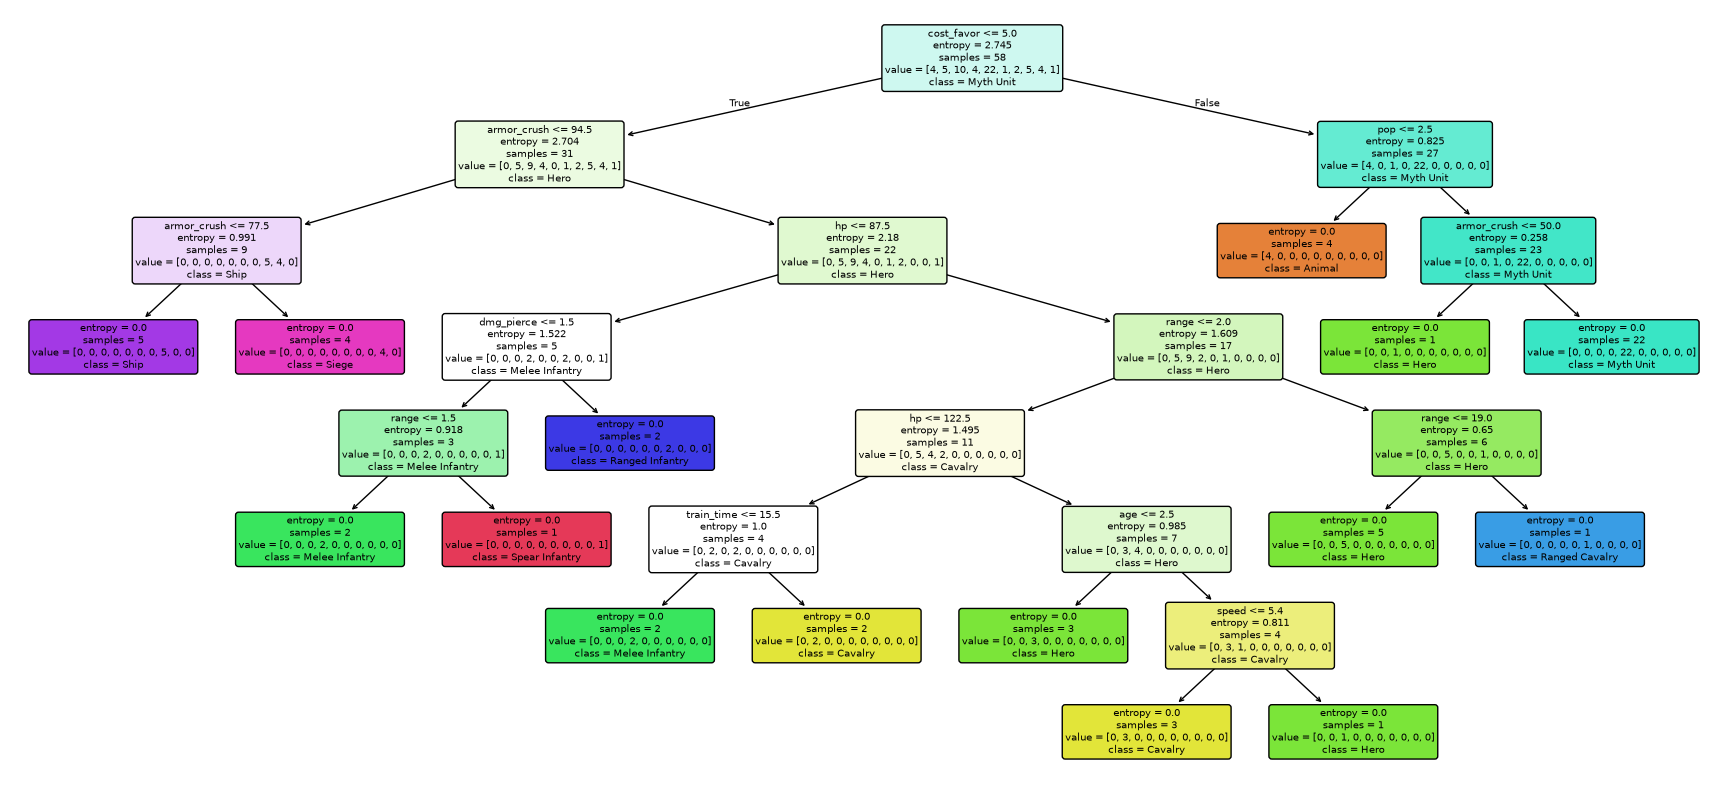

In [15]:
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = train_test_split(X_base, y, test_size=0.3, random_state=SEED)
arvore = pipe(DecisionTreeClassifier(criterion="entropy", random_state=SEED)).fit(X_train, y_train)
dt = arvore[-1]
print("Profundidade:", dt.get_depth(), "- Folhas:", dt.get_n_leaves())
y_pred = arvore.predict(X_test)
print("acurácia treino:", round(accuracy_score(y_train, arvore.predict(X_train)), 3),
      "| teste:", round(accuracy_score(y_test, y_pred), 3))
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(dt, feature_names=BASE, class_names=dt.classes_, filled=True, rounded=True, fontsize=7, ax=ax)
plt.show()

## 5. Poda da árvore (ccp_alpha) com validação aninhada
Escolher o alpha e relatar a acurácia nos mesmos folds deixa o número otimista. Aqui o alpha é escolhido por `GridSearchCV` **dentro** de cada fold externo.

In [16]:
caminho = DecisionTreeClassifier(criterion="entropy", random_state=SEED).cost_complexity_pruning_path(
    SimpleImputer(strategy="median").fit_transform(X_base), y)
alphas = np.unique(caminho.ccp_alphas)

busca_poda = GridSearchCV(
    pipe(DecisionTreeClassifier(criterion="entropy", random_state=SEED)),
    {"decisiontreeclassifier__ccp_alpha": alphas},
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy")
aninhada = cross_val_score(busca_poda, X_base, y,
                           cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED))
print("Árvore podada, acurácia aninhada: %.3f ± %.3f" % (aninhada.mean(), aninhada.std()))

Árvore podada, acurácia aninhada: 0.734 ± 0.067


## 6. Comparação dos modelos (atributos originais × atributos derivados)

In [17]:
def candidatos():
    return {
        "Árvore (entropia)":   (pipe(DecisionTreeClassifier(criterion="entropy", random_state=SEED))),
        "AdaBoost (prof. 1)":  (pipe(AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=50, random_state=SEED))),
        "AdaBoost (prof. 4)":  (pipe(AdaBoostClassifier(estimator=DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=SEED), n_estimators=50, random_state=SEED))),
        "Random Forest":       (pipe(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))),
        "Random Forest balanceada": (pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1))),
        "Extra Trees":         (pipe(ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))),
        "Regressão logística": (pipe(LogisticRegression(C=10, max_iter=5000), escala=True)),
        "SVM (RBF)":           (pipe(SVC(C=10), escala=True)),
    }

linhas = []
for nome_dados, dados in [("originais", X_base), ("originais + derivados", X_eng)]:
    for nome, modelo in candidatos().items():
        linhas.append({"atributos": nome_dados, "modelo": nome, **avaliar_cv(modelo, dados)})
tabela = pd.DataFrame(linhas).sort_values("acurácia", ascending=False)
display(tabela.round(3).reset_index(drop=True))

,atributos,modelo,acurácia,desvio acurácia,precisão (macro),F1 (macro)
0,originais,Random Forest,0.813,0.079,0.665,0.681
1,originais,Extra Trees,0.809,0.081,0.653,0.661
2,originais,Random Forest balanceada,0.808,0.092,0.644,0.655
3,originais + derivados,Regressão logística,0.804,0.066,0.661,0.662
4,originais + derivados,Random Forest balanceada,0.804,0.089,0.646,0.658
5,originais + derivados,SVM (RBF),0.799,0.071,0.677,0.681
6,originais,AdaBoost (prof. 4),0.799,0.081,0.649,0.657
7,originais + derivados,Random Forest,0.796,0.093,0.633,0.651
8,originais + derivados,Extra Trees,0.796,0.097,0.652,0.661
9,originais,Regressão logística,0.782,0.070,0.633,0.636


## 7. Ensemble por votação (Random Forest + AdaBoost + Regressão logística)
Modelos diferentes erram em unidades diferentes; a votação suave costuma ser mais estável que qualquer um isolado.

In [18]:
def criar_votacao():
    return pipe(VotingClassifier([
        ("rf",  RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
        ("ada", AdaBoostClassifier(estimator=DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=SEED),
                                   n_estimators=50, random_state=SEED)),
        ("lr",  make_pipeline(StandardScaler(), LogisticRegression(C=10, max_iter=5000))),
    ], voting="soft"))

for nome_dados, dados in [("originais", X_base), ("originais + derivados", X_eng)]:
    print(nome_dados, {k: round(v, 3) for k, v in avaliar_cv(criar_votacao(), dados).items()})

originais {'acurácia': np.float64(0.804), 'desvio acurácia': np.float64(0.067), 'precisão (macro)': np.float64(0.655), 'F1 (macro)': np.float64(0.662)}
originais + derivados {'acurácia': np.float64(0.806), 'desvio acurácia': np.float64(0.068), 'precisão (macro)': np.float64(0.662), 'F1 (macro)': np.float64(0.666)}


## 8. Estimativa honesta da acurácia (validação aninhada)
Ajusta hiperparâmetros da Random Forest dentro de cada fold externo.

In [19]:
grade = {"randomforestclassifier__max_features": ["sqrt", 0.5, None],
         "randomforestclassifier__min_samples_leaf": [1, 2]}
busca_rf = GridSearchCV(pipe(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
                        grade, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="accuracy")
aninhada_rf = cross_val_score(busca_rf, X_eng, y,
                              cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED))
print("Random Forest (aninhada): %.3f ± %.3f" % (aninhada_rf.mean(), aninhada_rf.std()))

Random Forest (aninhada): 0.811 ± 0.127


## 9. Matriz de confusão e relatório por classe (modelo final por votação, CV estratificada)

acurácia: 0.807


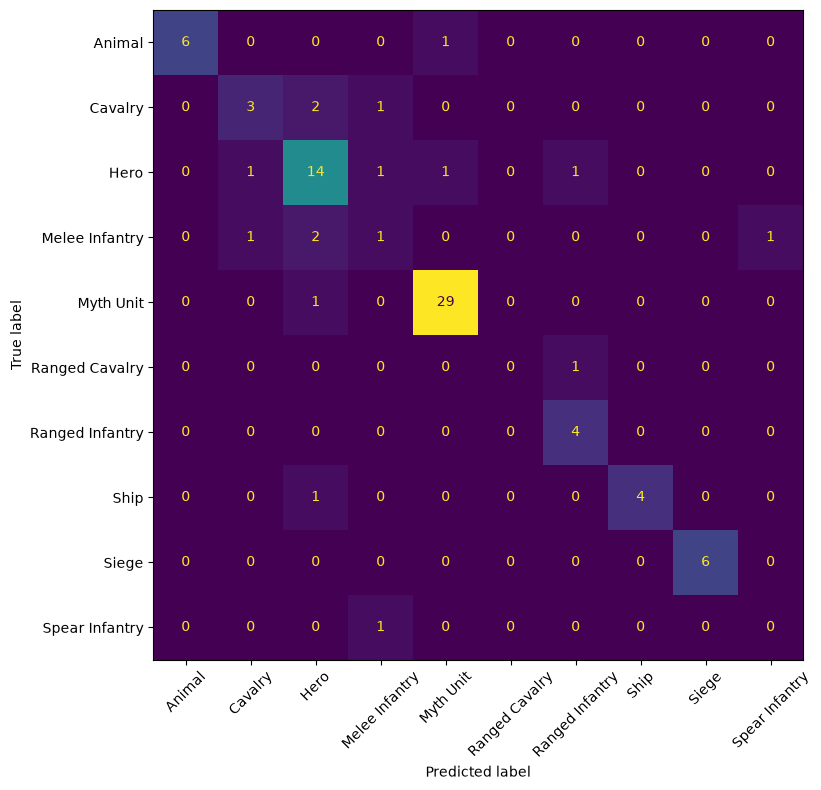

                 precision    recall  f1-score   support

         Animal       1.00      0.86      0.92         7
        Cavalry       0.60      0.50      0.55         6
           Hero       0.70      0.78      0.74        18
 Melee Infantry       0.25      0.20      0.22         5
      Myth Unit       0.94      0.97      0.95        30
 Ranged Cavalry       0.00      0.00      0.00         1
Ranged Infantry       0.67      1.00      0.80         4
           Ship       1.00      0.80      0.89         5
          Siege       1.00      1.00      1.00         6
 Spear Infantry       0.00      0.00      0.00         1

       accuracy                           0.81        83
      macro avg       0.62      0.61      0.61        83
   weighted avg       0.80      0.81      0.80        83



In [20]:
classes = sorted(y.unique())
p_cv = cross_val_predict(criar_votacao(), X_eng, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
print("acurácia:", round(accuracy_score(y, p_cv), 3))
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y, p_cv, labels=classes, xticks_rotation=45, ax=ax, colorbar=False)
plt.tight_layout(); plt.show()
print(classification_report(y, p_cv, zero_division=0))

Atributos mais importantes (Random Forest treinada com todos os dados)

In [21]:
rf_imp = pipe(RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)).fit(X_eng, y)
imp = pd.Series(rf_imp[-1].feature_importances_, index=X_eng.columns).sort_values(ascending=False)
display(imp.round(3).head(10))

cost_favor      0.141
armor_crush     0.107
hp              0.091
hp_por_pop      0.078
tem_favor       0.063
armor_pierce    0.061
armor_media     0.059
dmg_total       0.057
speed           0.048
armor_hack      0.046
dtype: float64

## 10. Treino final com os 83 registros e previsão das 10 unidades novas
As colunas `acordo` mostram onde os modelos divergem — essas unidades são as incertas e merecem atenção no relatório.

In [22]:
modelo_final = criar_votacao().fit(X_eng, y)

previsoes = teste.copy()
previsoes["classe_prevista"] = modelo_final.predict(T_eng)
probs = pd.DataFrame(modelo_final.predict_proba(T_eng), columns=modelo_final.classes_)
previsoes["confiança"] = probs.max(axis=1).round(2).values
previsoes["2ª opção"] = probs.apply(lambda r: r.sort_values().index[-2], axis=1).values
previsoes.index.name = "unidade_teste"

outros = {
    "Random Forest": pipe(RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)).fit(X_eng, y).predict(T_eng),
    "AdaBoost (prof. 4)": pipe(AdaBoostClassifier(estimator=DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=SEED), n_estimators=50, random_state=SEED)).fit(X_base, y).predict(T_base),
    "SVM (RBF)": pipe(SVC(C=10), escala=True).fit(X_eng, y).predict(T_eng),
}
comparacao = pd.DataFrame({"votação (final)": previsoes["classe_prevista"], **outros})
comparacao["todos concordam"] = comparacao.nunique(axis=1) == 1
display(previsoes)
display(comparacao)
previsoes.to_csv("previsoes_AgeOfMythology.csv")

,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor,classe_prevista,confiança,2ª opção
unidade_teste,,,,,,,,,,,,,,,,
0,3.0,5.0,12.0,0.0,0.0,1.0,800.0,60.0,60.0,80.0,3.60,19.0,15.0,Myth Unit,0.68,Hero
1,2.0,1.0,5.0,0.0,0.0,1.0,50.0,10.0,5.0,99.0,3.00,20.0,5.0,Animal,0.59,Hero
2,2.0,3.0,11.0,5.0,0.0,1.0,400.0,30.0,50.0,99.0,3.80,17.0,5.0,Hero,0.56,Myth Unit
3,3.0,2.0,0.0,6.0,0.0,20.0,60.0,15.0,15.0,99.0,3.75,12.0,0.0,Ranged Infantry,0.59,Ranged Cavalry
4,3.0,3.0,8.0,0.0,0.0,1.0,120.0,10.0,35.0,99.0,4.00,15.0,0.0,Cavalry,0.32,Melee Infantry
5,3.0,2.0,8.0,4.0,0.0,1.0,95.0,15.0,10.0,99.0,3.50,14.0,0.0,Melee Infantry,0.33,Hero
6,4.0,3.0,10.0,0.0,30.0,16.0,180.0,30.0,70.0,50.0,2.50,21.0,0.0,Siege,0.55,Myth Unit
7,4.0,3.0,11.0,10.0,0.0,1.0,140.0,15.0,40.0,99.0,3.50,22.0,0.0,Hero,0.42,Cavalry
8,2.0,3.0,10.0,0.0,8.0,1.0,175.0,50.0,25.0,80.0,4.00,26.0,10.0,Animal,0.33,Myth Unit


,votação (final),Random Forest,AdaBoost (prof. 4),SVM (RBF),todos concordam
unidade_teste,,,,,
0,Myth Unit,Myth Unit,Myth Unit,Myth Unit,True
1,Animal,Animal,Animal,Animal,True
2,Hero,Hero,Hero,Hero,True
3,Ranged Infantry,Ranged Infantry,Ranged Infantry,Ranged Infantry,True
4,Cavalry,Cavalry,Cavalry,Cavalry,True
5,Melee Infantry,Hero,Melee Infantry,Hero,False
6,Siege,Siege,Siege,Siege,True
7,Hero,Hero,Hero,Hero,True
8,Animal,Myth Unit,Myth Unit,Animal,False


FileNotFoundError: [Errno 2] No such file or directory: 'previsoes_AgeOfMythology.csv'